# Q9: One-Way ANOVA – Teaching Methods
**Aim:** To test whether mean exam scores differ among Traditional, Blended and Flipped teaching methods.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

### Load dataset (create it if the file is not given)

In [2]:
try:
    df = pd.read_csv("09_ANOVA_Teaching_Methods.csv")
except FileNotFoundError:
    np.random.seed(42)
    df = pd.DataFrame({"Student_ID": [f"S{i:03d}" for i in range(1, 151)],
                       "Teaching_Method": np.repeat(["Traditional", "Blended", "Flipped"], 50),
                       "Exam_Score": np.concatenate([np.random.normal(65, 8, 50), np.random.normal(72, 8, 50),
                                                     np.random.normal(76, 8, 50)]).clip(0, 100).round(1)})
g = df.groupby("Teaching_Method")["Exam_Score"]
names = list(g.groups)
groups = [g.get_group(m) for m in names]
k, N = len(groups), len(df)
df.head()

,Student_ID,Teaching_Method,Exam_Score
0,S001,Traditional,69.0
1,S002,Traditional,63.9
2,S003,Traditional,70.2
3,S004,Traditional,77.2
4,S005,Traditional,63.1


### 1. Descriptive statistics by method

In [3]:
g.agg(["count", "mean", "median", "var", "std"]).round(2)

,count,mean,median,var,std
Teaching_Method,,,,,
Blended,50,72.14,72.35,48.92,6.99
Flipped,50,75.69,76.15,65.99,8.12
Traditional,50,63.19,63.10,55.78,7.47


### 2. Hypotheses
- H0: μ_Traditional = μ_Blended = μ_Flipped
- H1: at least one mean differs, α = 0.05

### 3. Normality in each group

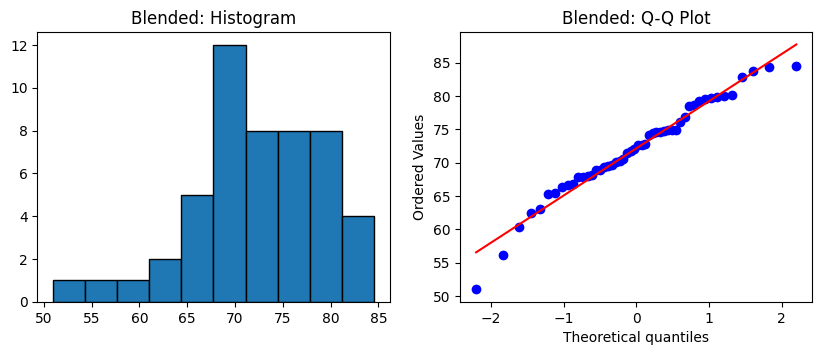

Blended: Shapiro p = 0.2537 -> Normal


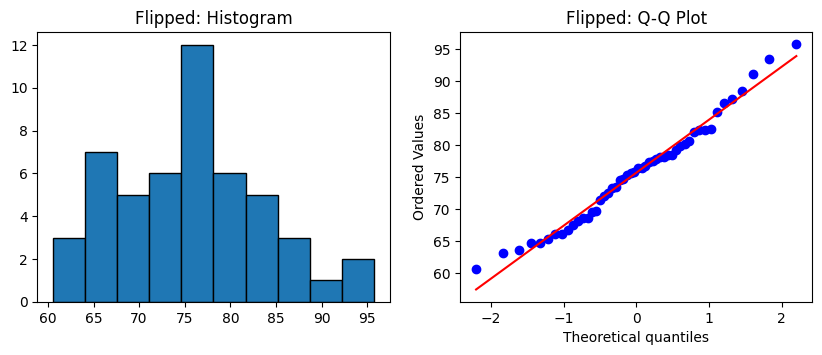

Flipped: Shapiro p = 0.4621 -> Normal


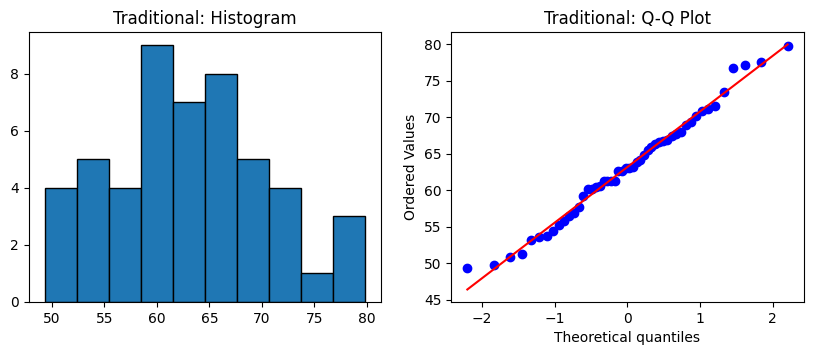

Traditional: Shapiro p = 0.6737 -> Normal


In [4]:
for m, s in zip(names, groups):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].hist(s, bins=10, edgecolor="black")
    ax[0].set_title(f"{m}: Histogram")
    stats.probplot(s, plot=ax[1])
    ax[1].set_title(f"{m}: Q-Q Plot")
    plt.show()
    sw_p = stats.shapiro(s).pvalue
    print(f"{m}: Shapiro p = {sw_p:.4f} ->", "Normal" if sw_p > 0.05 else "Not normal")

### 4. Levene's test (equal variances)

In [5]:
stat, p = stats.levene(*groups)
print(f"Levene = {stat:.3f}, p = {p:.4f} ->", "Equal variances" if p > 0.05 else "Unequal variances")

Levene = 0.544, p = 0.5818 -> Equal variances


### 5. One-way ANOVA

In [6]:
F, p_anova = stats.f_oneway(*groups)
print(f"F = {F:.3f}, df_between = {k - 1}, df_within = {N - k}, p = {p_anova:.6f}")
print("Reject H0: means differ" if p_anova < 0.05 else "Fail to reject H0: no significant difference")

F = 36.427, df_between = 2, df_within = 147, p = 0.000000
Reject H0: means differ


### 6. Tukey HSD post-hoc

In [7]:
if p_anova < 0.05:
    print("Group order:", {i: m for i, m in enumerate(names)})
    print(stats.tukey_hsd(*groups))

Group order: {0: 'Blended', 1: 'Flipped', 2: 'Traditional'}
Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -3.548     0.052    -7.120     0.024
 (0 - 2)      8.946     0.000     5.374    12.518
 (1 - 0)      3.548     0.052    -0.024     7.120
 (1 - 2)     12.494     0.000     8.922    16.066
 (2 - 0)     -8.946     0.000   -12.518    -5.374
 (2 - 1)    -12.494     0.000   -16.066    -8.922



Pairs with p < 0.05 (confidence interval not containing 0) differ significantly.

### 7. Effect size: eta² and omega²

In [8]:
grand = df["Exam_Score"].mean()
ss_b = sum(len(s) * (s.mean() - grand) ** 2 for s in groups)
ss_t = ((df["Exam_Score"] - grand) ** 2).sum()
ms_w = (ss_t - ss_b) / (N - k)
eta2 = ss_b / ss_t
omega2 = (ss_b - (k - 1) * ms_w) / (ss_t + ms_w)
print(f"Eta² = {eta2:.3f}, Omega² = {omega2:.3f}  (0.01 small, 0.06 medium, 0.14 large)")

Eta² = 0.331, Omega² = 0.321  (0.01 small, 0.06 medium, 0.14 large)


### 8. Boxplot, violin plot, mean comparison chart

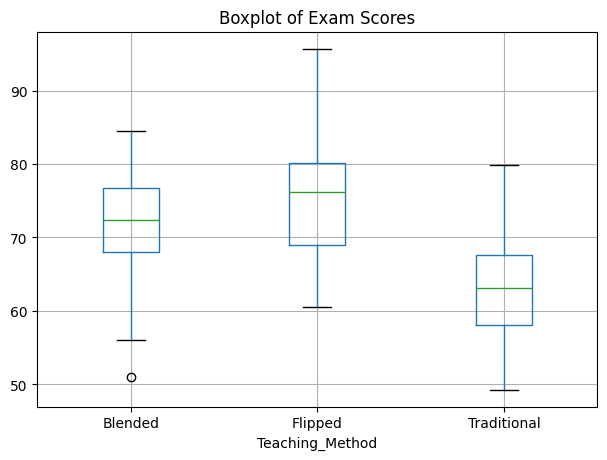

In [9]:
df.boxplot(column="Exam_Score", by="Teaching_Method", figsize=(7, 5))
plt.suptitle("")
plt.title("Boxplot of Exam Scores")
plt.show()

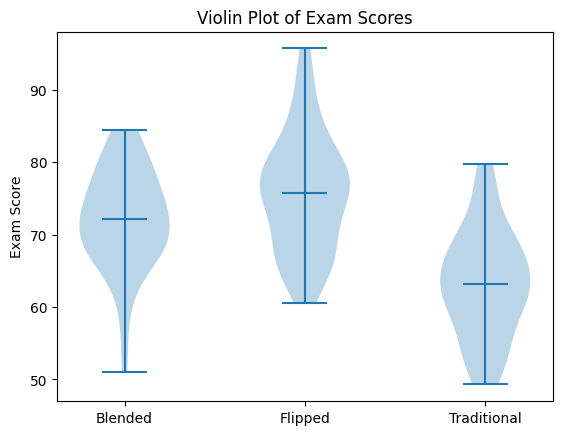

In [10]:
plt.violinplot(groups, showmeans=True)
plt.xticks(range(1, k + 1), names)
plt.ylabel("Exam Score")
plt.title("Violin Plot of Exam Scores")
plt.show()

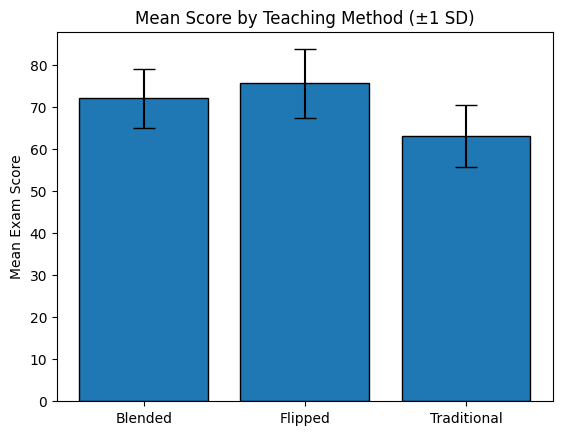

In [11]:
plt.bar(names, g.mean()[names], yerr=g.std()[names], capsize=8, edgecolor="black")
plt.ylabel("Mean Exam Score")
plt.title("Mean Score by Teaching Method (±1 SD)")
plt.show()

### 9. Percentage improvement in mean scores

In [12]:
mean = g.mean()
for a in names:
    for b in names:
        if mean[b] > mean[a]:
            print(f"{b} over {a}: {(mean[b] - mean[a]) / mean[a] * 100:.2f}%")

Flipped over Blended: 4.92%
Blended over Traditional: 14.16%
Flipped over Traditional: 19.77%


### 10. Kruskal-Wallis test (non-parametric check)

In [13]:
H, p_kw = stats.kruskal(*groups)
print(f"Kruskal-Wallis H = {H:.3f}, p = {p_kw:.6f} ->", "Reject H0" if p_kw < 0.05 else "Fail to reject H0")
print("Same conclusion as ANOVA" if (p_kw < 0.05) == (p_anova < 0.05) else "Different conclusion from ANOVA")

Kruskal-Wallis H = 49.223, p = 0.000000 -> Reject H0
Same conclusion as ANOVA


**Result:** One-way ANOVA with assumption checks, Tukey HSD, effect sizes and Kruskal-Wallis test was performed to compare teaching methods.